
---
date: "2026-10-25"
date-modified: last-modified
format:
  html:
    toc: true
---


# Faces, Vertices, and Extreme Points

**Prerequisites:** [Polyhedra and Polytopes](polyhedra-and-polytopes.ipynb) · [Hyperplanes and the Separation Theorem](hyperplane-separation-theorems.ipynb)

## 1\. Faces and Vertices

::: {#def-face-vertex}
## Face and Vertex

Let $C \subseteq \mathbb{R}^n$ be convex. A **face** of $C$ is a nonempty set of the form
$$
F = \{x \in C : a^{\mathsf T}x = \beta\}, \quad \text{where } a \ne 0 \text{ and } a^{\mathsf T}x \le \beta \text{ for all } x \in C,
$$
i.e. the intersection of $C$ with a [supporting hyperplane](hyperplane-separation-theorems.ipynb#def-supporting-hyperplane). Equivalently, $F$ is the (nonempty) set of points of $C$ where the linear function $a^{\mathsf T}x$ attains its maximum over $C$. A point $v \in C$ is a **vertex** if $\{v\}$ is a face: for some $a$,
$$
a^{\mathsf T}v > a^{\mathsf T}x \quad \text{for all } x \in C \setminus \{v\}.
$$
:::

A face is convex, being the intersection of $C$ with a hyperplane, and it is compact if $C$ is. The cube $[-1, 1]^3$ has faces of dimension $0$ (its $8$ corners, which are vertices), $1$ (its $12$ edges) and $2$ (its $6$ squares); for instance the edge $\{x : x_1 = x_2 = 1\}$ is the set of maximizers of $x_1 + x_2$.

::: {#def-extreme-point}
## Extreme Point

A point $x \in C$ is an **extreme point** of $C$ if it is not strictly inside a segment of $C$: there are no $y \ne z$ in $C$ and $t \in (0, 1)$ with $x = ty + (1-t)z$. The set of extreme points is $\operatorname{ext} C$.
:::

::: {#prp-vertex-is-extreme}
## Every Vertex Is an Extreme Point
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-vertex-is-extreme
Let $v$ be a vertex with vector $a$ as in @def-face-vertex, and suppose $v = ty + (1-t)z$ with $y \ne z$ in $C$, $t \in (0,1)$. Since $y \ne z$, one of them, say $y$, differs from $v$. So $a^{\mathsf T}y < a^{\mathsf T}v$, $a^{\mathsf T}z \le a^{\mathsf T}v$, and $a^{\mathsf T}v = t\,a^{\mathsf T}y + (1-t)\,a^{\mathsf T}z < a^{\mathsf T}v$, a contradiction. $\blacksquare$
:::

::: {#exm-extreme-points}
## Extreme Points of Some Sets

1. *Interior points are never extreme.* If $B(x, \rho) \subseteq C$ with $\rho > 0$, then $x$ is the midpoint of $x \pm \frac\rho2 e_1 \in C$.
2. *Closed disc $D = B(0, 1) \subseteq \mathbb{R}^2$.* Every boundary point $v$ ($\lVert v\rVert = 1$) is a vertex, hence extreme: by Cauchy–Schwarz $v^{\mathsf T}x \le \lVert x\rVert \le 1 = v^{\mathsf T}v$ on $D$, with equality only for $x = v$. So $\operatorname{ext} D$ is the whole circle.
3. *Closed half-plane.* Every point lies strictly inside a segment parallel to the boundary line, so there are no extreme points.
4. *Square $[-1,1]^2$.* The extreme points are the four corners (see [Vertices of Polytopes](vertices-of-polytopes.ipynb#exm-vertices-three-families)).
:::

::: {#exm-stadium}
## An Extreme Point That Is Not a Vertex

Let $S$ be the **stadium**, the set of points at distance $\le 1$ from the segment $[-1, 1] \times \{0\}$: the rectangle $[-1, 1] \times [-1, 1]$ with two half-discs attached. The point $q = (1, 1)$, where the top side meets the right half-disc, is an extreme point of $S$ but not a vertex.
:::

::: {.callout-tip collapse="true"}
## Proof of @exm-stadium
The points of $S$ satisfy $|x_2| \le 1$, and the points of $S$ with $x_2 = 1$ are exactly those of $[-1, 1] \times \{1\}$ (a point $(x_1, 1)$ has distance $\ge 1$ from the segment, with equality iff $x_1 \in [-1,1]$).

*Extreme.* If $q = ty + (1-t)z$ with $y, z \in S$, $t \in (0,1)$, then $1 = ty_2 + (1-t)z_2$ with $y_2, z_2 \le 1$ forces $y_2 = z_2 = 1$. So $y, z \in [-1,1] \times \{1\}$, and $q = (1,1)$ is an endpoint of that segment, which forces $y = z = q$.

*Not a vertex.* Suppose $a^{\mathsf T}q > a^{\mathsf T}x$ for all $x \in S \setminus \{q\}$. The disc $D = B((1, 0), 1)$ lies in $S$ and contains $q$, so $q$ maximizes $a^{\mathsf T}x$ over $D$. By Cauchy–Schwarz the maximum of $a^{\mathsf T}x$ over $D$ is attained only at $(1, 0) + a/\lVert a\rVert$; hence $a/\lVert a\rVert = q - (1, 0) = (0, 1)$, so $a = (0, a_2)$ with $a_2 > 0$. But then $a^{\mathsf T}(0, 1) = a_2 = a^{\mathsf T}q$ with $(0, 1) \in S \setminus \{q\}$, a contradiction. $\blacksquare$
:::

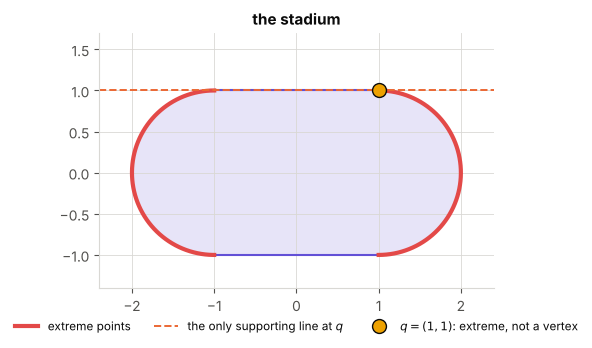

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID, FAINT = "#0b0b0b", "#52514e", "#d9d8d4", "#a3a29a"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})
fig, ax = plt.subplots(figsize=(7, 3.6))
th = np.linspace(-np.pi / 2, np.pi / 2, 200)
right = np.c_[1 + np.cos(th), np.sin(th)]; left = np.c_[-1 - np.cos(th), -np.sin(th)]
outline = np.vstack([right, [[-1, 1]], left, [[1, -1]]])
ax.fill(*outline.T, color=VIOLET, alpha=0.15)
ax.plot([-1, 1], [1, 1], color=VIOLET, lw=1.5); ax.plot([-1, 1], [-1, -1], color=VIOLET, lw=1.5)
ax.plot(*right.T, color=RED, lw=3, label="extreme points"); ax.plot(*left.T, color=RED, lw=3)
ax.axhline(1, color=ORANGE, lw=1.4, ls="--", label="the only supporting line at $q$")
ax.plot(1, 1, "o", color=YELLOW, mec=INK, ms=10, label="$q = (1,1)$: extreme, not a vertex")
ax.set_aspect("equal"); ax.set_xlim(-2.4, 2.4); ax.set_ylim(-1.4, 1.7); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=8.5)
ax.set_title("the stadium")
plt.tight_layout(); plt.show()


::: {#lem-extreme-not-in-hull}
## Extreme Points Cannot Be Generated by the Others

Let $C$ be convex and $x \in C$. Then $x \in \operatorname{ext} C$ if and only if $x \notin \operatorname{conv}(C \setminus \{x\})$. Consequently, if $C = \operatorname{conv} S$, then $\operatorname{ext} C \subseteq S$.
:::

::: {.callout-tip collapse="true"}
## Proof of @lem-extreme-not-in-hull
If $x$ is not extreme, $x = ty + (1-t)z$ with $y \ne z$ in $C$ and $t \in (0,1)$; then $y \ne x$ (if $y = x$, then $(1-t)(x - z) = 0$ gives $z = x = y$) and likewise $z \ne x$, so $x \in \operatorname{conv}(C \setminus \{x\})$.

Conversely let $x \in \operatorname{conv}(C \setminus \{x\})$. By [the description of the hull](convex-sets-and-convex-hulls.ipynb#thm-convex-hull-equivalence), $x = \sum_{i=1}^m t_ix_i$ with $x_i \in C \setminus \{x\}$, $t_i > 0$, $\sum t_i = 1$. Here $m \ge 2$, since $m = 1$ would give $x = x_1$. Write $x = t_1x_1 + (1 - t_1)x'$ with $x' = \sum_{i \ge 2}\frac{t_i}{1 - t_1}x_i \in C$ and $t_1 \in (0, 1)$. If $x' = x_1$, then $x = x_1$, impossible; so $x_1 \ne x'$ and $x$ is strictly inside the segment $[x_1, x']$ of $C$: not extreme.

For the consequence: if $x \in \operatorname{ext} C \setminus S$, then $S \subseteq C \setminus \{x\}$, so $x \in C = \operatorname{conv} S \subseteq \operatorname{conv}(C \setminus \{x\})$, contradicting the first part. $\blacksquare$
:::

::: {#lem-face-extreme}
## Extreme Points of a Face

If $F$ is a face of a convex set $C$, then $\operatorname{ext} F = F \cap \operatorname{ext} C$.
:::

::: {.callout-tip collapse="true"}
## Proof of @lem-face-extreme
Let $F = \{x \in C : a^{\mathsf T}x = \beta\}$ with $a^{\mathsf T}x \le \beta$ on $C$. A point of $F$ that is extreme in $C$ is extreme in $F$, since segments of $F$ are segments of $C$. Conversely let $y \in \operatorname{ext} F$ and suppose $y = tz + (1-t)w$ with $z \ne w$ in $C$, $t \in (0,1)$. Then $\beta = a^{\mathsf T}y = t\,a^{\mathsf T}z + (1-t)\,a^{\mathsf T}w$ with $a^{\mathsf T}z, a^{\mathsf T}w \le \beta$, which forces $a^{\mathsf T}z = a^{\mathsf T}w = \beta$. So $z, w \in F$, and $y$ is not extreme in $F$: a contradiction. $\blacksquare$
:::

## 2\. Minkowski's Theorem

::: {#thm-minkowski}
## Minkowski's Theorem

Every nonempty compact convex set $C \subseteq \mathbb{R}^n$ has extreme points, and
$$
C = \operatorname{conv}(\operatorname{ext} C) .
$$
By @lem-extreme-not-in-hull, $\operatorname{ext} C$ is contained in every set $S$ with $\operatorname{conv} S = C$: it is the smallest set generating $C$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-minkowski
Since $\operatorname{ext} C \subseteq C$ and $C$ is convex, $\operatorname{conv}(\operatorname{ext} C) \subseteq C$. We prove $C \subseteq \operatorname{conv}(\operatorname{ext} C)$ by induction on $d = \dim C$; then $\operatorname{ext} C \ne \emptyset$ follows from $C \ne \emptyset$.

*$d = 0$.* Then $\operatorname{aff} C$ is a point, so $C = \{x\}$ and $x$ is extreme.

*$d \ge 1$.* Assume the statement for all nonempty compact convex sets of dimension $< d$. Let $E = \operatorname{aff} C$ with direction $W \ne \{0\}$, fix $u \in W \setminus \{0\}$, and let $x \in C$. The line $x + \mathbb{R}u$ lies in $E$. The set $T = \{t \in \mathbb{R} : x + tu \in C\}$ is convex (as $C$ is), closed (as $C$ is closed and $t \mapsto x + tu$ is continuous), bounded (as $C$ is), and contains $0$; so $T = [t_-, t_+]$ with $t_- \le 0 \le t_+$. Put $y = x + t_+u$ and $z = x + t_-u$.

*Claim: $y$ lies in a face $F$ of $C$ with $\dim F < d$.* For $k \ge 1$ the point $p_k = y + \frac1k u$ lies in $E \setminus C$. Let $q_k$ be the [closest point](hyperplane-separation-theorems.ipynb#lem-closest-point) of $C$ to $p_k$ and $a_k = (p_k - q_k)/\lVert p_k - q_k\rVert$. Since $p_k, q_k \in E$, $a_k \in W$. By the closest point lemma, $a_k^{\mathsf T}c \le a_k^{\mathsf T}q_k < a_k^{\mathsf T}p_k$ for all $c \in C$. By [Bolzano–Weierstrass](Bolzano-Weierstrass-theorem.ipynb) a subsequence of the unit vectors $a_k$ converges to a unit vector $a$, which lies in $W$ ($W$ is closed). Letting $k \to \infty$ along it, $a^{\mathsf T}c \le a^{\mathsf T}y$ for all $c \in C$. So $F = \{c \in C : a^{\mathsf T}c = a^{\mathsf T}y\}$ is a face containing $y$. If $C$ were contained in the hyperplane $H(a, a^{\mathsf T}y)$, then $a^{\mathsf T}$ would be constant on $C$, hence on $E$ ([this lemma](polyhedra-and-polytopes.ipynb#lem-affine-hull)), so $a^{\mathsf T}w = 0$ for all $w \in W$, in particular $a^{\mathsf T}a = 0$: impossible. Hence $C \not\subseteq H$, and $\dim F \le d - 1$ by [this lemma](polyhedra-and-polytopes.ipynb#lem-dimension-drop).

*Conclusion.* $F$ is nonempty, compact and convex, so by the induction hypothesis and @lem-face-extreme, $y \in F = \operatorname{conv}(\operatorname{ext} F) \subseteq \operatorname{conv}(\operatorname{ext} C)$. Applying the claim with $-u$ in place of $u$ gives $z \in \operatorname{conv}(\operatorname{ext} C)$. If $t_+ = t_-$, then $x = y$. Otherwise $x = \lambda y + (1 - \lambda)z$ with $\lambda = \frac{-t_-}{t_+ - t_-} \in [0, 1]$, so $x \in \operatorname{conv}(\operatorname{ext} C)$, which is convex. $\blacksquare$
:::

::: {.callout-note}
## Intuition: Push to the Boundary, Then Drop a Dimension
Through any point of $C$ draw a line inside $\operatorname{aff} C$; it leaves $C$ at two points of the relative boundary. At such a point $C$ has a supporting hyperplane (a limit of separating hyperplanes, exactly as for [supporting hyperplanes](hyperplane-separation-theorems.ipynb#thm-supporting-hyperplane)), which cuts out a face of smaller dimension, where the same argument applies again. Extreme points of faces are extreme points of $C$.
:::

::: {.callout-warning}
## Both Hypotheses Are Needed
A closed half-plane (convex, closed, unbounded) and an open disc (convex, bounded, not closed) have no extreme points at all, so neither is the convex hull of its extreme points. For a compact convex set the extreme points need not be vertices (@exm-stadium), and they may form an infinite set: the whole circle for a disc, two closed half-circles for the stadium.
:::